# Block-bootstrap uncertainty for footprint climatologies

A footprint climatology is usually reported as a single raster with a contour
drawn at 80 % of the source weight, and that contour is then used to decide
something consequential: which land-cover pixels the tower "sees", whether a
satellite product may be compared against the flux, whether a treatment plot
lies inside the source area. Drawn that way the contour is a **point estimate
with no error bar** — it is one realisation of a season of turbulence, and a
different season, or the same season resampled, would put the line somewhere
else.

[`fluxfootprints.bootstrap_footprint_uncertainty`](../fluxfootprints.rst) puts an
error bar on it. It runs a **moving-block bootstrap** over the half-hourly
record and reports, on the same grid as the climatology:

| band | meaning |
|---|---|
| `p_include_{R}` | probability that a pixel falls inside the *R* % source area |
| `w_mean`, `w_p05`, `w_p50`, `w_p95` | the per-pixel weight distribution across members |
| `w_cv` | coefficient of variation, masked where the mean weight is negligible |

`p_include_80` is the band that replaces the hard contour. A pixel with
`p_include_80 = 0.98` is inside the 80 % source area under essentially any
resampling of the season; a pixel at 0.45 is a coin flip, and any land-cover
statistic that depends on it is not defensible.

## What this notebook does

It works through the module end to end on a real site — **US-UTE**, a 2 m
cropland tower near Escalante, Utah — in the three phases the module is built
around:

1. **Accumulate.** Run the footprint model once per block and cache `B` rasters
   (`accumulate_blocks` → `BlockStack`).
2. **Resample.** Form bootstrap members as integer combinations of those cached
   blocks (`block_bootstrap` → `BootstrapResult`).
3. **Write.** Export every band to one multiband GeoTIFF (`write_geotiff`).

Along the way it covers the two choices that actually change the answer — the
**block length**, and the distinction between **random** spread and a
**systematic** sonic-azimuth offset (`rotate_climatology`) — and the diagnostic
that tells you whether the result can be trusted at all, the **in-domain
captured fraction**.

> **Runtime.** Phase 1 runs the Kljun et al. (2015) model over 3 549 half-hours and takes
> roughly two to three minutes. Phases 2 and 3 take under a second, which is the
> whole point of caching blocks rather than periods.

## 1. Setup

Beyond the package itself this needs only NumPy, pandas, matplotlib and
rasterio. The `logging.disable` call silences the per-period chatter the
footprint model emits — over 3 000 periods it would otherwise bury the output.

In [1]:
import logging
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import LinearSegmentedColormap

from fluxfootprints import FFPModel
from fluxfootprints.bootstrap_footprint_uncertainty import (
    BlockStack,
    GridSpec,
    accumulate_blocks,
    block_bootstrap,
    block_labels,
    rotate_climatology,
    source_area_mask,
    write_geotiff,
)

# The footprint model logs once per period; 3000+ lines is not useful here.
logging.disable(logging.CRITICAL)
warnings.filterwarnings("ignore", category=RuntimeWarning)

DATA = Path("..") / ".." / "data"                 # repository data/ directory
WORK = Path(tempfile.mkdtemp(prefix="fp-bootstrap-"))   # scratch GeoTIFF

SITE = "US-UTE"
TOWER_LAT, TOWER_LON = 37.7353, -111.5708   # UFLUX Escalante, UT
Z_M, Z_0 = 2.0, 0.05                        # (z - d) [m], roughness length [m]
CRS = "EPSG:32612"                          # UTM 12N

print(f"scratch directory: {WORK}")

scratch directory: C:\Users\PAULIN~1\AppData\Local\Temp\fp-bootstrap-s6ffx36l


### Plot styling

One palette for the whole notebook, so the same quantity is always the same
colour. Three sequential ramps, each a single hue light→dark, and one diverging
blue↔red with a neutral grey midpoint for the signed difference map in §10:

- **blue** — footprint weight (a density)
- **aqua** — inclusion probability (the bootstrap deliverable)
- **orange** — coefficient of variation (relative spread)

The categorical hues used for line charts are slots 1–3 of the reference
palette, which is validated colour-vision-safe across all pairs.

In [2]:
%matplotlib inline

# Categorical slots 1-3 (validated CVD-safe across all pairs).
C_BLUE, C_ORANGE, C_AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
SURFACE = "#fcfcfb"

def ramp(name, stops):
    """One-hue sequential colormap, near-surface at zero to dark at the maximum."""
    return LinearSegmentedColormap.from_list(name, stops)

CM_WEIGHT = ramp("weight", [SURFACE, "#cde2fb", "#86b6ef", "#3987e5",
                            "#256abf", "#184f95", "#0d366b"])
CM_PROB   = ramp("prob",   [SURFACE, "#cdeee1", "#8ad9bd", "#3fc196",
                            "#1baf7a", "#128257", "#0a5539"])
CM_CV     = ramp("cv",     [SURFACE, "#fbe0d3", "#f6b898", "#f08d5e",
                            "#eb6834", "#b74a20", "#7d3014"])
# Diverging: warm/cool poles, neutral grey midpoint - never a hue at the middle.
CM_DIFF   = ramp("diff",   ["#0d366b", "#256abf", "#86b6ef", "#f0efec",
                            "#f0a3a2", "#d03b3b", "#8a1f1f"])

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK,
    "axes.titlesize": 10,
    "axes.titleweight": "semibold",
    "axes.titlelocation": "left",
    "axes.labelsize": 9,
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "grid.linestyle": "-",          # solid hairlines; dashed grids read as thresholds
    "axes.axisbelow": True,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.frameon": False,
    "legend.fontsize": 8,
    "lines.linewidth": 1.8,
    "font.size": 9,
    "font.family": "sans-serif",
    "figure.dpi": 120,
})

## 2. The tower record

US-UTE is an AmeriFlux cropland site on flat terrain at 1 729 m. The receptor
sits 2 m above the displacement height over a roughness of about 5 cm, which
makes for a compact footprint — a few hundred metres at most — and that in turn
makes a modest domain adequate.

The module's period adapter needs six half-hourly drivers:

| column | symbol | role |
|---|---|---|
| `WS` | $\overline{u}$ | mean wind speed at $z_m$ |
| `WD` | — | wind direction, meteorological convention |
| `USTAR` | $u_*$ | friction velocity |
| `MO_LENGTH` | $L$ | Obukhov length |
| `V_SIGMA` | $\sigma_v$ | lateral velocity standard deviation |
| `PBLH_F` | $h$ | boundary-layer height |

We take one summer season. Rows missing any driver are dropped up front so the
period count below is the count the model will actually attempt.

In [3]:
REQUIRED = ["WS", "WD", "USTAR", "MO_LENGTH", "V_SIGMA", "PBLH_F"]

raw = pd.read_csv(
    DATA / "station_data" / "US-UTE_HH_202401220330_202409021900.csv",
    na_values=[-9999.0],
)
raw.index = pd.to_datetime(
    raw["TIMESTAMP_START"].astype("int64").astype(str), format="%Y%m%d%H%M"
)

season = raw.loc["2024-06-01":"2024-08-31", REQUIRED].dropna()

print(f"{SITE}: {len(season)} complete half-hours")
print(f"  {season.index.min():%Y-%m-%d %H:%M} to {season.index.max():%Y-%m-%d %H:%M}")
print(f"  spanning {(season.index.max() - season.index.min()).days + 1} calendar days")
season.describe().T[["count", "mean", "min", "max"]].round(2)

US-UTE: 3549 complete half-hours
  2024-06-18 16:30 to 2024-08-31 23:30
  spanning 75 calendar days


,count,mean,min,max
WS,3549.0,2.64,0.35,7.94
WD,3549.0,249.08,0.01,359.99
USTAR,3549.0,0.26,0.02,0.87
MO_LENGTH,3549.0,22.08,-3682.34,4255.85
V_SIGMA,3549.0,0.82,0.15,3.50
PBLH_F,3549.0,584.48,108.92,2095.41


### Why blocks, and how long?

A bootstrap that resampled individual half-hours would treat consecutive periods
as independent draws. They are not. Footprint geometry is set almost entirely by
wind direction and by the stability that controls the along-wind extent, and at
a site like this both are **diurnally periodic** — daytime up-valley flow,
nighttime drainage. Resampling half-hours independently would shuffle 3 a.m.
drainage flow into midday convection, destroy the diurnal pairing, and report an
interval far narrower than the season actually supports.

The figure below makes that concrete. The left panel is the wind rose; the right
is the lag autocorrelation of the wind-direction unit vector
$(\cos\theta, \sin\theta)$, which is the circular-safe way to autocorrelate an
angle.

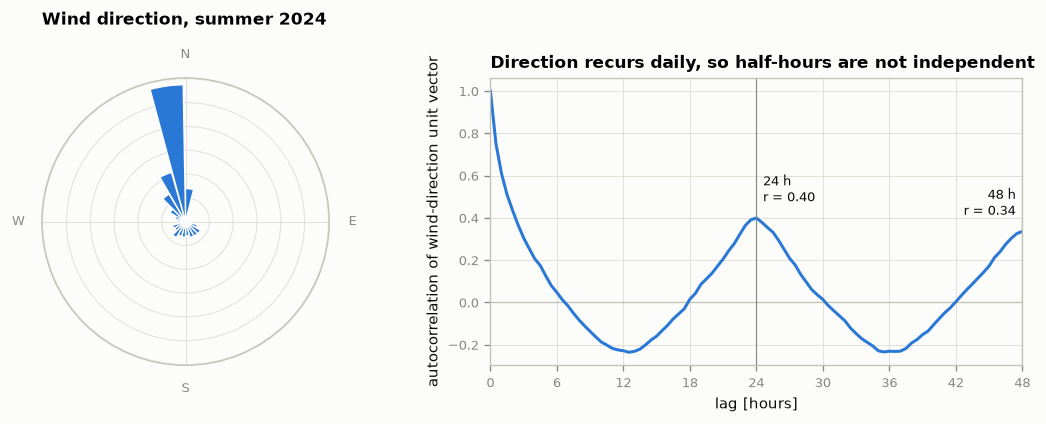

r at  6 h: +0.05   (within-day memory is gone)
r at 12 h: -0.23   (anti-phase: day flow vs night drainage)
r at 24 h: +0.40   (the diurnal cycle repeats)
r at 48 h: +0.34   (and still persists across days)

vector-mean wind direction 335 deg - flow is from the NNW, so the
source area will sit NNW of the tower.


In [4]:
regular = season.reindex(
    pd.date_range(season.index.min(), season.index.max(), freq="30min")
)
theta = np.deg2rad(regular["WD"])
lags = np.arange(0, 97)                      # 0 to 48 h in half-hour steps
acf = 0.5 * np.array([
    theta.pipe(np.cos).autocorr(l) + theta.pipe(np.sin).autocorr(l) for l in lags
])
hours = lags / 2.0

fig, (ax_rose, ax_acf) = plt.subplots(
    1, 2, figsize=(9.2, 3.6),
    subplot_kw=None, gridspec_kw={"width_ratios": [1, 1.35]},
)
ax_rose.remove()
ax_rose = fig.add_subplot(1, 2, 1, projection="polar")

edges = np.deg2rad(np.arange(0, 361, 15))
counts, _ = np.histogram(np.deg2rad(season["WD"]), bins=edges)
ax_rose.bar(edges[:-1], counts / counts.sum() * 100, width=np.deg2rad(14),
            align="edge", color=C_BLUE, edgecolor=SURFACE, linewidth=0.8)
ax_rose.set_theta_zero_location("N")
ax_rose.set_theta_direction(-1)
ax_rose.set_xticks(np.deg2rad([0, 90, 180, 270]))
ax_rose.set_xticklabels(["N", "E", "S", "W"], color=MUTED, fontsize=8)
ax_rose.set_yticklabels([])
ax_rose.grid(color=GRID, linewidth=0.6)
ax_rose.set_title("Wind direction, summer 2024", pad=14)

ax_acf.axhline(0.0, color="#c3c2b7", linewidth=0.8)
ax_acf.plot(hours, acf, color=C_BLUE)
for h, dx_lbl, ha in ((24, 4, "left"), (48, -4, "right")):
    ax_acf.axvline(h, color=MUTED, linewidth=0.7)
    ax_acf.annotate(f"{h} h\nr = {acf[h * 2]:.2f}", xy=(h, acf[h * 2]),
                    xytext=(dx_lbl, 10), textcoords="offset points",
                    fontsize=8, color=INK, ha=ha)
ax_acf.set_xlabel("lag [hours]")
ax_acf.set_ylabel("autocorrelation of wind-direction unit vector")
ax_acf.set_xlim(0, 48)
ax_acf.set_xticks([0, 6, 12, 18, 24, 30, 36, 42, 48])
ax_acf.set_title("Direction recurs daily, so half-hours are not independent")
fig.tight_layout()
plt.show()

print(f"r at  6 h: {acf[12]:+.2f}   (within-day memory is gone)")
print(f"r at 12 h: {acf[24]:+.2f}   (anti-phase: day flow vs night drainage)")
print(f"r at 24 h: {acf[48]:+.2f}   (the diurnal cycle repeats)")
print(f"r at 48 h: {acf[96]:+.2f}   (and still persists across days)")

# The vector mean is the only meaningful "average" of an angle: the arithmetic
# mean of WD is nonsense when the distribution straddles 0/360.
rad = np.deg2rad(season["WD"])
vec = np.rad2deg(np.arctan2(np.sin(rad).mean(), np.cos(rad).mean())) % 360
print(f"\nvector-mean wind direction {vec:.0f} deg - flow is from the NNW, so the")
print(f"source area will sit NNW of the tower.")

The rose is strongly bimodal-to-unimodal about the north: nearly 30 % of
half-hours arrive from 345–360°, with a secondary spread through the south.
That concentration is what makes the source area compact, and it is also why a
few degrees of azimuth error matters so much here (§10).

The autocorrelation falls through zero within about six hours, swings **negative
at 12 h** — midday flow is close to the reverse of the small-hours flow — and
returns to $r \approx 0.4$ at 24 h and $0.33$ at 48 h. Two things follow:

- **A block must contain a whole diurnal cycle.** Anything shorter splits the
  day/night pair, so the block length floor here is one day. This is the
  `block_days=1` default.
- **Day-to-day memory has not vanished either.** The residual correlation at
  48 h argues that 2–3 day blocks would be defensible, and we test that
  in §9 rather than asserting it.

## 3. The grid

`GridSpec` is a regular metric grid centred on the tower: `x` positive east, `y`
positive north, both in metres from the receptor. `GridSpec.square` is the
convenient constructor — a half-width and a cell size.

Domain size is a real decision, not a formality. Too small and the footprint is
truncated at the edge, the captured fraction drops, and an "80 % source area"
silently becomes 80 % of whatever stayed inside the box. Too large and you pay
for empty cells in every one of the 3 271 model runs. For a 2 m receptor a
±300 m box at 5 m resolution captures about 95 % of the source weight while
keeping the grid to 120 × 120.

In [5]:
grid = GridSpec.square(
    half_width=300.0, dx=5.0,
    tower_lat=TOWER_LAT, tower_lon=TOWER_LON, crs=CRS,
)

print(f"shape        {grid.shape}  (ny, nx)")
print(f"cell         {grid.dx:g} x {grid.dy:g} m  = {grid.cell_area:g} m^2")
print(f"x extent     {grid.x.min():+.1f} to {grid.x.max():+.1f} m  (east positive)")
print(f"y extent     {grid.y.min():+.1f} to {grid.y.max():+.1f} m  (north positive)")
print(f"crs          {grid.crs}")

# Plot extent in metres from the tower, for imshow. Row 0 is the north edge,
# hence origin="upper".
EXTENT = [grid.x.min() - grid.dx / 2, grid.x.max() + grid.dx / 2,
          grid.y.min() - grid.dy / 2, grid.y.max() + grid.dy / 2]

shape        (120, 120)  (ny, nx)
cell         5 x 5 m  = 25 m^2
x extent     -297.5 to +297.5 m  (east positive)
y extent     -297.5 to +297.5 m  (north positive)
crs          EPSG:32612


### Array order: the one thing that silently corrupts the output

The footprint models in this package return arrays indexed `(x, y)` with `y`
ascending north. GeoTIFFs are `(row, col)` with row 0 at the **north** edge.
Getting this wrong produces a plausible-looking raster that is transposed or
flipped, and no downstream check will catch it.

`GridSpec.to_raster_order` does the conversion and validates the shape while it
is at it. Pass `model_order="xy"` for this package's models, `"yx"` for a model
that already returns row-major arrays. The demonstration below uses a marker
placed at a known corner so the transformation is visible rather than asserted.

In [6]:
# A 3x3 toy grid with a single spike at the far north-east corner.
toy = GridSpec.square(half_width=1.5, dx=1.0, tower_lat=TOWER_LAT, tower_lon=TOWER_LON)
model_out = np.zeros(toy.shape)          # (x, y) order as the models emit it
model_out[-1, -1] = 1.0                  # max x (east), max y (north)

print("model order (x, y), y ascending north:")
print(model_out)
print("\nraster order (row, col), row 0 = north:")
print(toy.to_raster_order(model_out, model_order="xy"))
print("\n-> the spike moves to the top-right cell, i.e. north-east. Correct.")

# The shape check catches a wrong model_order or a mismatched domain.
try:
    grid.to_raster_order(np.zeros((10, 10)), model_order="xy")
except ValueError as exc:
    print(f"\nmismatched input raises: {exc}")

model order (x, y), y ascending north:
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 1.]]

raster order (row, col), row 0 = north:
[[0. 0. 1.]
 [0. 0. 0.]
 [0. 0. 0.]]

-> the spike moves to the top-right cell, i.e. north-east. Correct.

mismatched input raises: footprint shape (10, 10) does not match grid (120, 120); check model_order and the model's domain settings


## 4. Wiring in the footprint model

`accumulate_blocks` does not know anything about a particular footprint model.
It takes a **`period_footprint` callable**: given one row of the driver frame,
return a 2-D footprint density on the grid (units $\mathrm{m^{-2}}$), or `None`
if the period is unusable. Everything model-specific lives in that one function,
which is what makes the module reusable across the Kljun, Kormann–Meixner and
Lagrangian models in this package.

The filters below are not optional garnish — they are the validity envelope of
Kljun et al. (2015), and periods outside it produce numbers rather than
footprints:

| filter | reason |
|---|---|
| $h > 10\ \mathrm{m}$, $u_* > 0.1\ \mathrm{m\,s^{-1}}$, $\sigma_v > 0$ | physically meaningless otherwise |
| $20 z_0 < z_m < 0.8 h$ | Kljun et al. (2015) eq. 27 — receptor above the roughness sublayer and inside the boundary layer |
| $z_m / L \geq -15.5$ | the parameterisation's convective limit |

<div class="alert alert-warning">

**Note on `ffp_period_adapter`.** The module ships a convenience adapter of the
same shape, but its call signature predates the current `FFPModel`: it passes
scalars (`zm=`, `ol=`, …) where `FFPModel` now takes a one-row DataFrame, and it
reads a `fclim_2d` key where `run()` now returns `footprint_climatology`. Calling
it raises `TypeError: FFPModel.__init__() missing 1 required positional
argument: 'df'`. The adapter below is the same logic against the current API;
use it until the shipped one is updated.

</div>

In [7]:
def ffp_adapter(grid: GridSpec, z_m: float, z_0: float):
    """Return a ``period_footprint`` callable backed by the Kljun et al. (2015) model.

    Returns None for any period outside the parameterisation's validity envelope,
    which tells ``accumulate_blocks`` to skip it rather than fail.
    """
    domain = [float(grid.x.min()), float(grid.x.max()),
              float(grid.y.min()), float(grid.y.max())]

    def period_footprint(row: pd.Series) -> np.ndarray | None:
        L, h, ustar = float(row.MO_LENGTH), float(row.PBLH_F), float(row.USTAR)
        sigmav = float(row.V_SIGMA)

        if h <= 10.0 or ustar <= 0.1 or sigmav <= 0.0:
            return None
        if not (20.0 * z_0 < z_m < 0.8 * h):        # Kljun et al. (2015) eq. 27
            return None
        if z_m / L < -15.5:                         # convective limit
            return None

        one = pd.DataFrame(
            {"zm": [z_m], "z0": [z_0], "h": [h], "ol": [L], "sigmav": [sigmav],
             "ustar": [ustar], "wind_dir": [float(row.WD)], "umean": [float(row.WS)]},
            index=[row.name],
        )
        result = FFPModel(one, domain=domain, dx=grid.dx, dy=grid.dy,
                          verbosity=0).run()
        return np.asarray(result["footprint_climatology"])   # dims (x, y)

    return period_footprint


period_footprint = ffp_adapter(grid, Z_M, Z_0)

# Smoke-test on one period before committing to 3271 of them.
probe = season.iloc[100]
fp = period_footprint(probe)
print(f"{probe.name}: WD={probe.WD:.0f} deg, u*={probe.USTAR:.2f}, L={probe.MO_LENGTH:+.0f} m")
print(f"  footprint {fp.shape} in (x, y) order, "
      f"integrates to {fp.sum() * grid.cell_area:.3f} of the source")

2024-06-20 18:30:00: WD=166 deg, u*=0.34, L=+184 m
  footprint (120, 120) in (x, y) order, integrates to 0.950 of the source


## 5. Phase 1 — accumulate the blocks

This is the step the module's design is built around. A moving-block bootstrap
resamples *blocks*, so every bootstrap member is a non-negative integer
combination of the per-block footprint sums. Running the model once per block
and caching `B ≈ 75` rasters instead of `N = 3 271` means the resampling in §7
is a single matrix multiply, and 500 members cost essentially nothing.

`block_labels` assigns the contiguous calendar blocks; `accumulate_blocks` calls
it internally, but it is worth looking at directly.

In [8]:
labels = block_labels(season.index, block_days=1)
print(f"{np.unique(labels).size} daily blocks, labels {labels.min()}..{labels.max()}")
print(f"first five rows -> blocks {labels[:5]}")
print(f"periods in the busiest block: {np.bincount(labels).max()}")

75 daily blocks, labels 0..74
first five rows -> blocks [0 0 0 0 0]
periods in the busiest block: 48


Now the expensive part. `accumulate_blocks` iterates the frame, calls the
adapter, converts each footprint to raster order, and adds it into its block's
slot. Periods that return `None`, raise, or produce non-finite values are
counted as skipped rather than aborting the run.

Two details worth knowing before reading the output:

- **Footprints are accumulated raw, not individually renormalised.** Rescaling
  each period to unit mass first would give a long, heavily truncated nocturnal
  footprint the same total weight as a short, fully captured daytime one, which
  manufactures variance at the domain edge. The member climatology is normalised
  once, at the end.
- **The in-domain captured mass is tracked per block**, so truncation is
  measurable rather than assumed.

In [9]:
%%time
blocks = accumulate_blocks(
    season,
    grid,
    period_footprint,
    block_days=1,
    model_order="xy",
    progress=True,
)

  0/3549 periods


  500/3549 periods


  750/3549 periods


  1000/3549 periods


  1250/3549 periods


...

  3000/3549 periods


  3250/3549 periods


  3500/3549 periods


  done: 3271 usable, 278 skipped, 75 blocks


CPU times: total: 2min 4s
Wall time: 2min 6s


In [10]:
print(f"blocks kept        {blocks.n_blocks}")
print(f"usable periods     {int(blocks.n_periods.sum())} of {len(season)}")
print(f"periods per block  {blocks.n_periods.min()}-{blocks.n_periods.max()} "
      f"(median {int(np.median(blocks.n_periods))})")
print(f"mean capture       {blocks.mean_capture:.3f}")
print(f"cached stack       {blocks.stack.shape} float32 = "
      f"{blocks.stack.nbytes / 1e6:.1f} MB")

blocks kept        75
usable periods     3271 of 3549
periods per block  9-48 (median 44)
mean capture       0.955
cached stack       (75, 120, 120) float32 = 4.3 MB


### Reading the block diagnostics

`BlockStack` drops empty blocks in `__post_init__`, so `n_blocks` is the number
of blocks that actually carry data. Both diagnostics below matter for what
follows.

**Periods per block** is the bootstrap's effective weighting. A block with 9
usable half-hours contributes as much to a member as one with 48 whenever it is
drawn, and blocks are drawn with equal probability. Heavily gap-filled seasons
therefore give more erratic members, which is a property of the record, not a
bug — the bootstrap is telling you the truth about your data coverage.

**Captured fraction per block** is the truncation diagnostic. Values well below
1 mean the domain is clipping the footprint and the R % contours are R % of the
captured mass, not of the real footprint.

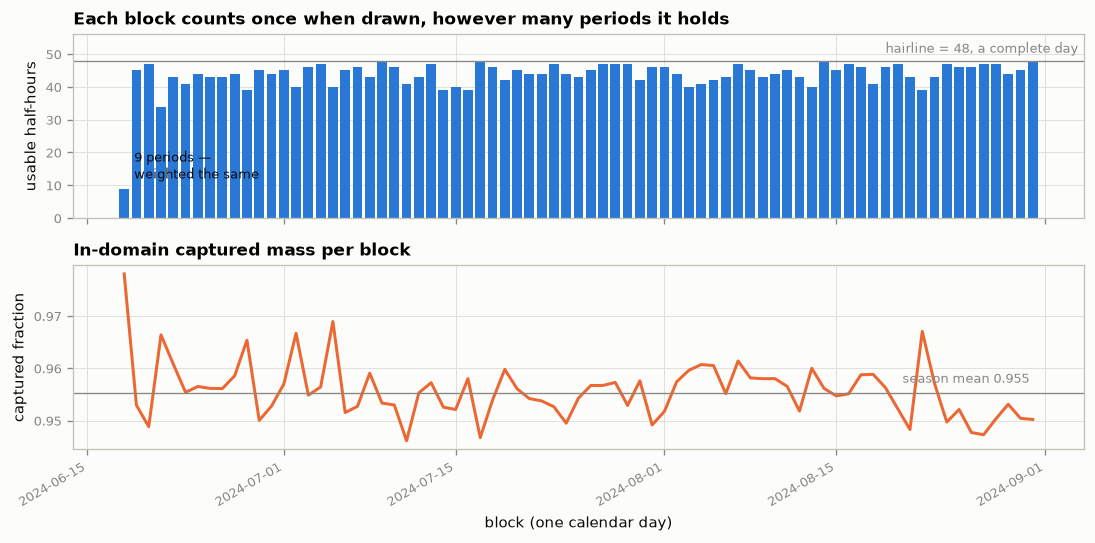

per-block capture ranges 0.946 to 0.978
highest R level that is safely below it: 0.90


In [11]:
day = pd.to_datetime(season.index.min().normalize()) + pd.to_timedelta(
    np.asarray(blocks.labels), unit="D"
)
per_block_capture = blocks.captured / blocks.n_periods

fig, (ax_n, ax_c) = plt.subplots(2, 1, figsize=(9.2, 4.6), sharex=True)

ax_n.bar(day, blocks.n_periods, width=0.8, color=C_BLUE, linewidth=0)
ax_n.axhline(48, color=MUTED, linewidth=0.8)
ax_n.annotate("hairline = 48, a complete day", xy=(0.995, 0.96),
              xycoords="axes fraction", ha="right", va="top",
              fontsize=8, color=MUTED)
thin = int(np.argmin(blocks.n_periods))
ax_n.annotate(f"{blocks.n_periods[thin]} periods —\nweighted the same",
              xy=(day[thin], blocks.n_periods[thin]), xytext=(6, 6),
              textcoords="offset points", fontsize=8, color=INK)
ax_n.set_ylabel("usable half-hours")
ax_n.set_ylim(0, 56)
ax_n.set_title("Each block counts once when drawn, however many periods it holds")

ax_c.plot(day, per_block_capture, color=C_ORANGE)
ax_c.axhline(blocks.mean_capture, color=MUTED, linewidth=0.8)
ax_c.annotate(f"season mean {blocks.mean_capture:.3f}", xy=(day[-1], blocks.mean_capture),
              xytext=(-2, 6), textcoords="offset points", fontsize=8,
              color=MUTED, ha="right")
ax_c.set_ylabel("captured fraction")
ax_c.set_xlabel("block (one calendar day)")
ax_c.set_title("In-domain captured mass per block")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

lo, hi = per_block_capture.min(), per_block_capture.max()
print(f"per-block capture ranges {lo:.3f} to {hi:.3f}")
print(f"highest R level that is safely below it: {np.floor(lo * 20) / 20:.2f}")

Capture sits in a tight band, 0.946 to 0.978 — **and that number sets the
ceiling on the R levels you may legitimately request.** About 4 % of the source
weight falls outside the ±300 m box, so a "90 % source area" computed here is
really 90 % of the captured 96 %. That is acceptable for R = 0.5 and R = 0.8,
and it is why this notebook does not push to R = 0.95 on this domain. If you
need higher levels, widen the domain — no amount of resampling will recover mass
that was never on the grid.

Two cautions on reading this diagnostic:

- `mean_capture` inherits the underlying `FFPModel` climatology normalisation,
  which on larger domains can push the per-period integral a little **above**
  1.0. Treat it as a truncation *index* rather than a strict fraction: near 1 is
  good, drifting well below 1 is a warning, and the shape of the curve across
  blocks is the thing to watch.
- A flat capture curve, as here, means truncation is a property of the *domain*,
  not of particular weather. A curve with excursions would point at specific
  days — typically stable nights with long footprints — and those are the days
  worth inspecting individually.

## 6. The point estimate, for reference

Before the bootstrap, the conventional answer: sum every block, normalise once,
and cut contours with `source_area_mask`. This is the raster most footprint
workflows stop at, and it is the thing we are about to put an error bar on.

`source_area_mask(w, R)` returns the **smallest set of pixels holding fraction
R** of the in-domain weight — it sorts pixels by weight descending and takes the
cumulative sum, which is the standard definition of an R % source area and makes
no assumption that the region is connected or convex.

In [12]:
point = blocks.stack.sum(axis=0).astype(np.float64)
point /= point.sum() * grid.cell_area            # normalise once, at the end
print(f"normalised climatology integrates to {point.sum() * grid.cell_area:.6f}")

LEVELS = (0.5, 0.8, 0.9)
masks = {R: source_area_mask(point, R) for R in LEVELS}

rows = []
for R in LEVELS:
    npx = int(masks[R].sum())
    rows.append({"R": f"{R:.0%}", "pixels": npx,
                 "area [ha]": npx * grid.cell_area / 1e4,
                 "equiv. radius [m]": np.sqrt(npx * grid.cell_area / np.pi)})
pd.DataFrame(rows).set_index("R").round(2)

normalised climatology integrates to 1.000000


,pixels,area [ha],equiv. radius [m]
R,,,
50%,53,0.13,20.54
80%,280,0.70,47.20
90%,801,2.00,79.84


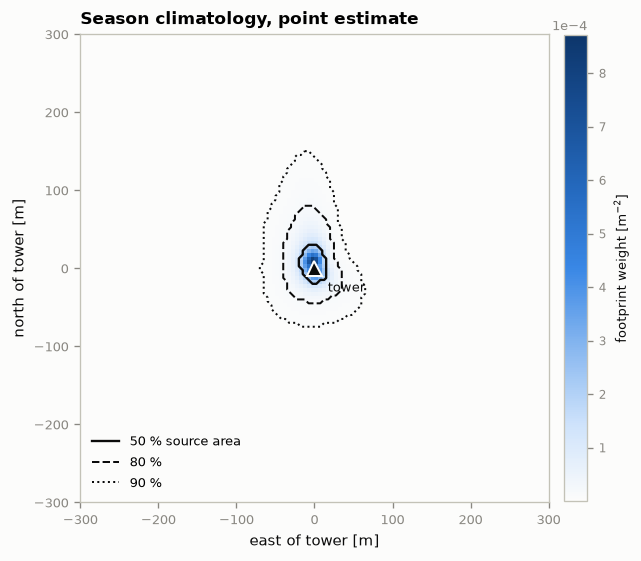

In [13]:
fig, ax = plt.subplots(figsize=(5.4, 5.0))
im = ax.imshow(point, origin="upper", extent=EXTENT, cmap=CM_WEIGHT,
               interpolation="nearest")

# One contour per level, all in the same ink - the labels carry identity,
# not the colour, so the weight ramp keeps the colour channel to itself.
cs = ax.contour(masks[0.5].astype(float), levels=[0.5], origin="upper",
                extent=EXTENT, colors=[INK], linewidths=1.4)
for R, ls in ((0.8, "--"), (0.9, ":")):
    ax.contour(masks[R].astype(float), levels=[0.5], origin="upper",
               extent=EXTENT, colors=[INK], linewidths=1.2, linestyles=ls)

ax.plot(0, 0, marker="^", markersize=9, color=INK,
        markeredgecolor=SURFACE, markeredgewidth=1.2, zorder=5)
ax.annotate("tower", xy=(0, 0), xytext=(8, -14), textcoords="offset points",
            fontsize=8, color=INK)

handles = [plt.Line2D([], [], color=INK, lw=1.4, label="50 % source area"),
           plt.Line2D([], [], color=INK, lw=1.2, ls="--", label="80 %"),
           plt.Line2D([], [], color=INK, lw=1.2, ls=":", label="90 %")]
ax.legend(handles=handles, loc="lower left")

ax.set_xlabel("east of tower [m]")
ax.set_ylabel("north of tower [m]")
ax.set_title("Season climatology, point estimate")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
cb.set_label("footprint weight [m$^{-2}$]", fontsize=8)
cb.ax.tick_params(labelsize=7)
cb.formatter.set_powerlimits((0, 0))
fig.tight_layout()
plt.show()

The source area sits just north-north-west of the tower, matching the
vector-mean wind direction of 335°, and the 80 % area is 0.70 ha — a patch under
100 m across inside a 600 m box. That headroom is deliberate: it is what
keeps the captured fraction near 1, and it is why the maps in §8 are worth
zooming into.

Every line in this figure is drawn with full confidence, and none of that
confidence is warranted. Nothing here says whether the dashed line would land in
the same place given a different sample of the same season. That is the question
§7 answers.

## 7. Phase 2 — the bootstrap

`block_bootstrap` draws `B` blocks with replacement, `n_members` times. Because
each member is just `counts @ block_stack`, all 500 members are formed in one
chunked matmul and the whole phase runs in well under a second.

The arguments that matter:

- **`levels`** — the R values to evaluate. Keep `max(levels)` comfortably below
  the captured fraction from §5.
- **`min_capture`** — members whose capture falls below this are dropped. It
  defaults to `max(levels) + 0.05`, so `(0.5, 0.8, 0.9)` implies 0.95.
- **`cv_floor_quantile`** — `w_cv` is masked to NaN where the mean weight falls
  below this quantile of the weight distribution. The CV of a near-zero weight
  is arbitrarily large and would swamp the map. The default of 0.5 keeps the
  upper half of *pixels*, which is the right instinct but the wrong number here:
  this footprint occupies about 6 % of the grid, so a 0.5 floor would paint CV
  across a vast low-weight halo that nobody cares about. Set the floor so the
  retained pixels roughly match the source area you are reporting — for a
  90 % source area of ~800 of 14 400 pixels, that is **0.94**.
- **`seed`** — set it. A bootstrap that cannot be reproduced cannot be reviewed.

In [14]:
# Choose the CV floor from the geometry rather than accepting the default:
# retain roughly the pixels inside the largest source area we report.
cv_floor_q = 1.0 - masks[max(LEVELS)].sum() / masks[max(LEVELS)].size
print(f"{int(masks[max(LEVELS)].sum())} of {masks[max(LEVELS)].size} pixels lie "
      f"inside the {max(LEVELS):.0%} source area")
print(f"-> cv_floor_quantile = {cv_floor_q:.2f} (the default 0.50 would keep "
      f"{masks[max(LEVELS)].size // 2} pixels)")

801 of 14400 pixels lie inside the 90% source area
-> cv_floor_quantile = 0.94 (the default 0.50 would keep 7200 pixels)


In [15]:
%%time
result = block_bootstrap(
    blocks,
    n_members=500,
    levels=LEVELS,
    min_capture=None,               # -> max(levels) + 0.05 = 0.95
    cv_floor_quantile=cv_floor_q,   # keep CV over the 90 % source area only
    seed=0,
)

CPU times: total: 1.06 s
Wall time: 679 ms


In [16]:
print(f"members kept    {result.n_members}")
print(f"members dropped {result.n_dropped}")
print(f"member capture  {result.member_capture.min():.4f} - "
      f"{result.member_capture.max():.4f}")
print(f"bands           {[name for name, _ in result.bands()]}")
print()
for k, v in result.meta.items():
    print(f"  {k:<14} {v}")

members kept    500
members dropped 0
member capture  0.9538 - 0.9570
bands           ['p_include_50', 'p_include_80', 'p_include_90', 'w_mean', 'w_p05', 'w_p50', 'w_p95', 'w_cv']

  n_blocks       75
  n_periods      3271
  mean_capture   0.9553053634692791
  min_capture    0.9500000000000001
  cv_floor       3.5848896877155283e-06
  seed           0


Nothing was dropped, but look at how close the call was: `min_capture` is 0.95
and the *minimum* member capture is 0.9538. Shift the domain in a little, or ask
for `levels=(0.5, 0.8, 0.95)` — which would raise the threshold to 0.99 — and
every member fails, at which point `block_bootstrap` raises rather than quietly
returning an ensemble of one. That guard is doing real work here.

Note also how narrow the member-capture range is: 0.9538 to 0.9570. Each member
averages 75 blocks, so block-to-block truncation differences wash out almost
entirely. **Capture is a property of the domain, not of the resampling** — the
bootstrap cannot rescue a domain that is too small, and a tight capture range is
not evidence that the domain is adequate.

## 8. Reading the result

Four bands, four questions:

- **`w_mean`** — where is the source area? Essentially reproduces §6.
- **`w_cv`** — how variable is the weight in each pixel, relative to its own
  mean? Masked below the median weight.
- **`p_include_80` / `p_include_90`** — how often does this pixel make the cut?
  This is the band that replaces the hard contour.

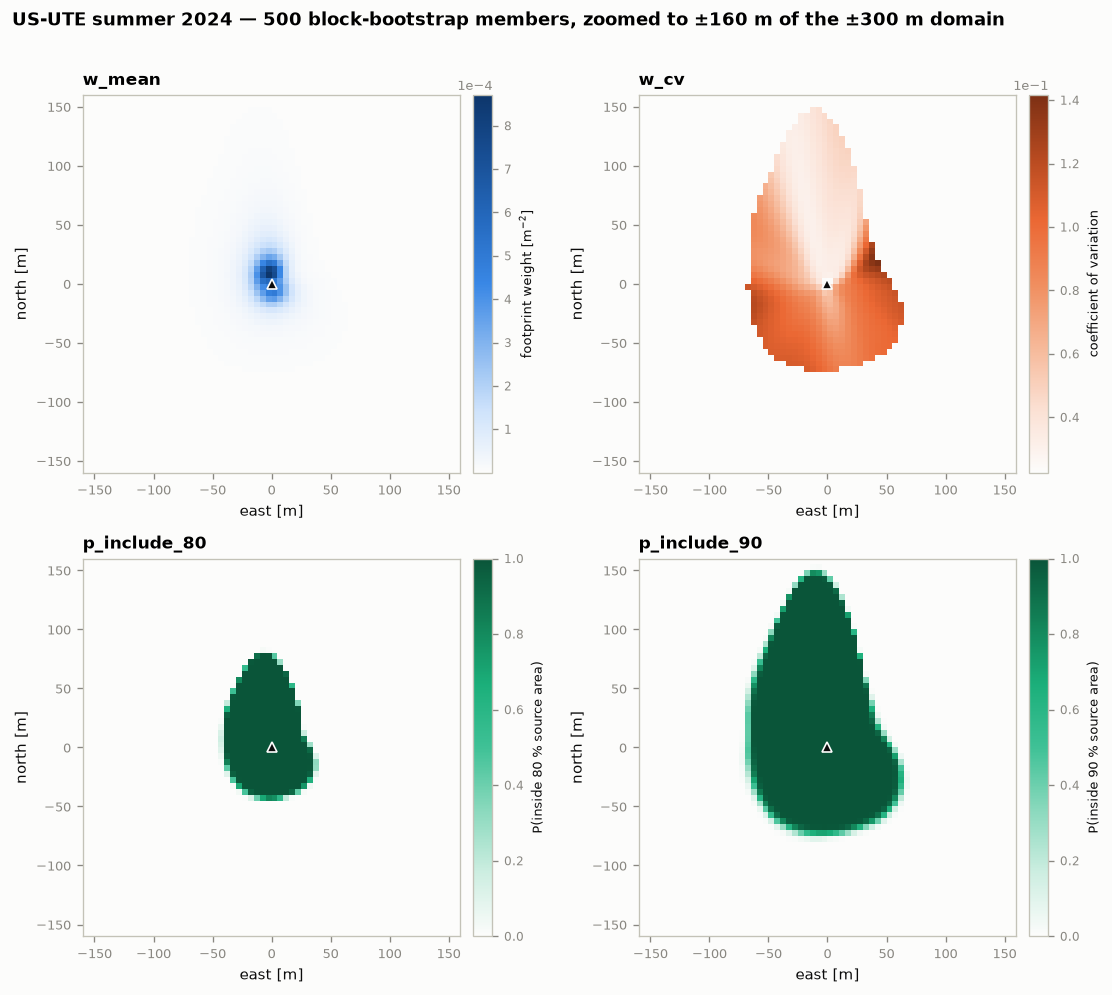

In [17]:
VIEW = 160.0     # the footprint occupies a small part of the domain; zoom in

panels = [
    ("w_mean",       result.w_mean,         CM_WEIGHT, "footprint weight [m$^{-2}$]", None),
    ("w_cv",         result.w_cv,           CM_CV,     "coefficient of variation", None),
    ("p_include_80", result.p_include[0.8], CM_PROB,   "P(inside 80 % source area)", (0, 1)),
    ("p_include_90", result.p_include[0.9], CM_PROB,   "P(inside 90 % source area)", (0, 1)),
]

fig, axes = plt.subplots(2, 2, figsize=(9.4, 8.4))
for ax, (name, arr, cmap, label, lim) in zip(axes.ravel(), panels):
    kw = {"vmin": lim[0], "vmax": lim[1]} if lim else {}
    im = ax.imshow(arr, origin="upper", extent=EXTENT, cmap=cmap,
                   interpolation="nearest", **kw)
    ax.plot(0, 0, marker="^", markersize=6, color=INK,
            markeredgecolor=SURFACE, markeredgewidth=1.0, zorder=5)
    ax.set_xlim(-VIEW, VIEW)
    ax.set_ylim(-VIEW, VIEW)
    ax.set_aspect("equal")
    ax.set_title(name)
    ax.set_xlabel("east [m]")
    ax.set_ylabel("north [m]")
    ax.grid(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    cb.set_label(label, fontsize=8)
    cb.ax.tick_params(labelsize=7)
    if lim is None:
        cb.formatter.set_powerlimits((0, 0))
fig.suptitle(f"{SITE} summer 2024 — {result.n_members} block-bootstrap members, "
             f"zoomed to ±{VIEW:.0f} m of the ±300 m domain",
             x=0.02, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

Two features of `w_cv` are worth reading rather than skipping past. The pale
wedge running NNW from the tower — **low relative spread straight down the
prevailing wind** — is there because almost every block contributes weight along
that axis, so resampling barely changes it. The saturated flanks on either side
are directions that only some blocks visit, so which blocks get drawn matters a
great deal. **Relative uncertainty is lowest where the footprint is most
certain of its direction**, which is the same reason the margin in the next
table hugs the sides of the source area rather than its nose.

### Core, margin, and what you may actually claim

The useful way to read `p_include` is to split it into three zones:

- **core** ($p \geq 0.95$) — inside the source area under essentially any
  resampling. Claim these pixels.
- **margin** ($0.05 < p < 0.95$) — the pixels the point-estimate contour decides
  arbitrarily. Any land-cover fraction or flux attribution that turns on these
  is not defensible without stating the uncertainty.
- **outside** ($p \leq 0.05$).

The margin-to-core ratio is the one-number summary of how sharp the contour is.

In [18]:
zones = []
for R in result.levels:
    p = result.p_include[R]
    core = int((p >= 0.95).sum())
    margin = int(((p > 0.05) & (p < 0.95)).sum())
    zones.append({
        "R": f"{R:.0%}",
        "core [ha]": core * grid.cell_area / 1e4,
        "margin [ha]": margin * grid.cell_area / 1e4,
        "point est. [ha]": int(masks[R].sum()) * grid.cell_area / 1e4,
        "margin / core": margin / max(core, 1),
    })
zone_table = pd.DataFrame(zones).set_index("R").round(3)
zone_table

,core [ha],margin [ha],point est. [ha],margin / core
R,,,,
50%,0.120,0.022,0.132,0.188
80%,0.650,0.102,0.700,0.158
90%,1.828,0.338,2.002,0.185


The point estimate lands between core and core + margin at every level, as it
should. The margin runs 15–20 % of the core area throughout — so the 80 %
source area at this site is **0.65 ha of confident core plus about 0.10 ha of
genuinely ambiguous edge**.

It is worth being precise about what that margin looks like on the ground,
because "16 % uncertain" sounds worse than it is. The figure below overlays the
point-estimate 80 % boundary on `p_include_80`. The ambiguous rim is one to two
cells wide — **roughly ±5 to 10 m of positional uncertainty on the contour** —
which is reassuring for a homogeneous field and disqualifying if a field edge,
road or canopy break runs within 10 m of that line.

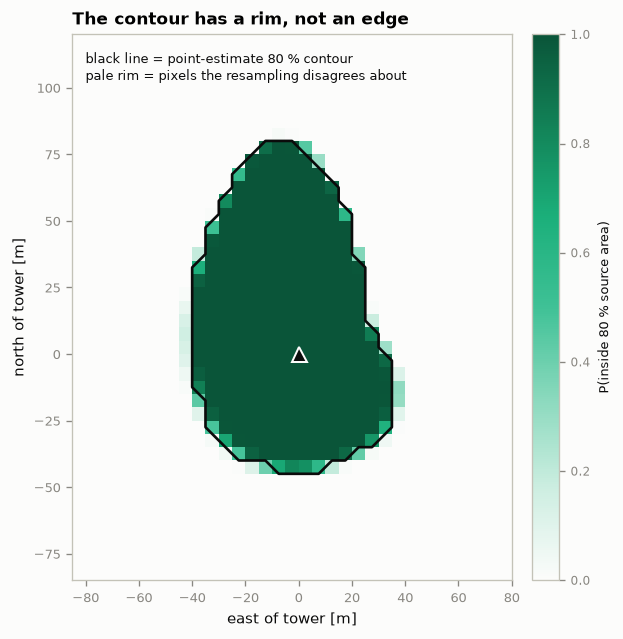

In [19]:
# Zoom to the 80 % source area plus a small margin, in metres from the tower.
rows_i, cols_i = np.where(result.p_include[0.8] > 0.05)
pad = 8
r0, r1 = max(rows_i.min() - pad, 0), min(rows_i.max() + pad, grid.shape[0] - 1)
c0, c1 = max(cols_i.min() - pad, 0), min(cols_i.max() + pad, grid.shape[1] - 1)
# Row 0 is north, so the top of the window is the larger y.
zoom_extent = [grid.x[c0] - grid.dx / 2, grid.x[c1] + grid.dx / 2,
               grid.y[grid.shape[0] - 1 - r1] - grid.dy / 2,
               grid.y[grid.shape[0] - 1 - r0] + grid.dy / 2]
sub = np.s_[r0:r1 + 1, c0:c1 + 1]

fig, ax = plt.subplots(figsize=(6.2, 5.4))
im = ax.imshow(result.p_include[0.8][sub], origin="upper", extent=zoom_extent,
               cmap=CM_PROB, vmin=0, vmax=1, interpolation="nearest")
ax.contour(masks[0.8][sub].astype(float), levels=[0.5], origin="upper",
           extent=zoom_extent, colors=[INK], linewidths=1.6)
ax.plot(0, 0, marker="^", markersize=9, color=INK,
        markeredgecolor=SURFACE, markeredgewidth=1.2, zorder=5)
ax.annotate("black line = point-estimate 80 % contour\n"
            "pale rim = pixels the resampling disagrees about",
            xy=(0.03, 0.97), xycoords="axes fraction", va="top",
            fontsize=8, color=INK)
ax.set_xlabel("east of tower [m]")
ax.set_ylabel("north of tower [m]")
ax.set_aspect("equal")
ax.set_title("The contour has a rim, not an edge")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
cb.set_label("P(inside 80 % source area)", fontsize=8)
cb.ax.tick_params(labelsize=7)
fig.tight_layout()
plt.show()

## 9. Block length is the choice that moves the answer

Section 2 argued from the autocorrelation that blocks must be at least a day.
Here we measure what block length actually does to the interval.

Re-running `accumulate_blocks` for each candidate length would cost several
minutes per setting. It is also unnecessary: a `k`-day block is exactly the sum
of `k` consecutive daily blocks, so the daily `BlockStack` can be coarsened
arithmetically. The helper below is worth keeping — it turns a block-length
sensitivity test into a couple of seconds.

In [20]:
def coarsen(stack: BlockStack, factor: int) -> BlockStack:
    """Merge groups of ``factor`` consecutive daily blocks into longer blocks.

    Exactly equivalent to re-running ``accumulate_blocks`` with
    ``block_days=factor``, because a block sum is additive.
    """
    if factor == 1:
        return stack
    group = np.asarray(stack.labels) // factor
    uniq = np.unique(group)
    ny, nx = stack.grid.shape
    merged = np.zeros((uniq.size, ny, nx), dtype=np.float32)
    n_per = np.zeros(uniq.size, dtype=np.int64)
    cap = np.zeros(uniq.size, dtype=np.float64)
    for i, g in enumerate(uniq):
        sel = group == g
        merged[i] = stack.stack[sel].sum(axis=0)
        n_per[i] = stack.n_periods[sel].sum()
        cap[i] = stack.captured[sel].sum()
    return BlockStack(stack=merged, n_periods=n_per, captured=cap,
                      labels=list(uniq), grid=stack.grid)


sweep = []
for days in (1, 2, 3, 5, 7, 14):
    bs = coarsen(blocks, days)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        r = block_bootstrap(bs, n_members=300, levels=(0.8,), min_capture=0.90,
                            cv_floor_quantile=cv_floor_q, seed=1)
        warned = any("blocks" in str(w.message) for w in caught)
    p = r.p_include[0.8]
    core = int((p >= 0.95).sum()) * grid.cell_area / 1e4
    margin = int(((p > 0.05) & (p < 0.95)).sum()) * grid.cell_area / 1e4
    sweep.append({
        "block_days": days,
        "B": bs.n_blocks,
        "core [ha]": core,
        "margin [ha]": margin,
        "core + margin [ha]": core + margin,
        "median CV": float(np.nanmedian(r.w_cv)),
        "B < 20": warned,
    })
sweep = pd.DataFrame(sweep).set_index("block_days")
sweep.round(3)

,B,core [ha],margin [ha],core + margin [ha],median CV,B < 20
block_days,,,,,,
1,75,0.648,0.102,0.750,0.072,False
2,38,0.642,0.110,0.752,0.070,False
3,25,0.638,0.122,0.760,0.072,False
5,15,0.632,0.132,0.765,0.079,True
7,11,0.638,0.128,0.765,0.073,True
14,6,0.628,0.140,0.768,0.080,True


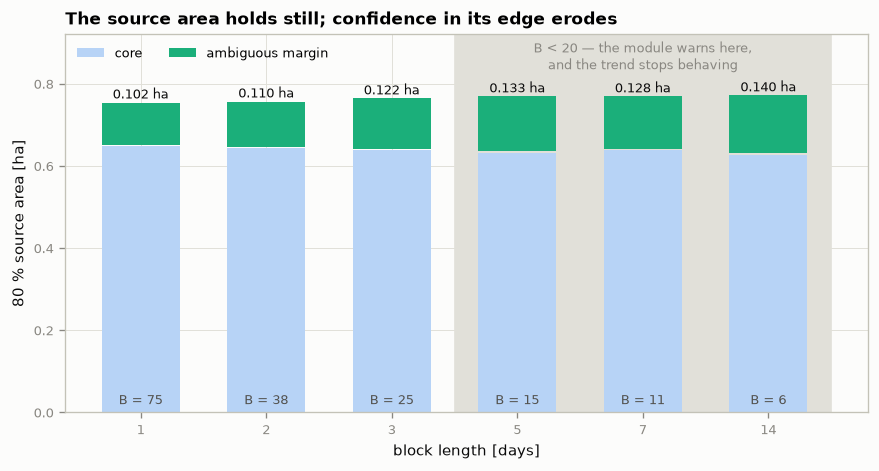

In [21]:
x = np.arange(len(sweep))
fig, ax = plt.subplots(figsize=(7.4, 4.0))

# Shade the settings the module itself flags as unreliable.
first_warn = int(np.argmax(sweep["B < 20"].to_numpy()))
ax.axvspan(first_warn - 0.5, len(sweep) - 0.5, color=GRID, zorder=0)
ax.annotate("B < 20 — the module warns here,\nand the trend stops behaving",
            xy=((first_warn + len(sweep) - 1) / 2, 0.985),
            xycoords=("data", "axes fraction"), ha="center", va="top",
            fontsize=8, color=MUTED)

# Stacked: the core recedes so the margin - the quantity that actually moves -
# carries the saturated hue. A 2px surface gap separates the segments.
ax.bar(x, sweep["core [ha]"], width=0.62, color="#b7d3f6", linewidth=0,
       label="core")
ax.bar(x, sweep["margin [ha]"], width=0.62, bottom=sweep["core [ha]"] + 0.004,
       color=C_AQUA, linewidth=0, label="ambiguous margin")

for xi, (_, row) in zip(x, sweep.iterrows()):
    ax.annotate(f"{row['margin [ha]']:.3f} ha",
                xy=(xi, row["core [ha]"] + row["margin [ha]"] + 0.014),
                ha="center", fontsize=8, color=INK)
    ax.annotate(f"B = {int(row['B'])}", xy=(xi, 0.02), ha="center",
                fontsize=8, color="#52514e")

ax.set_xticks(x, [str(d) for d in sweep.index])
ax.set_xlabel("block length [days]")
ax.set_ylabel("80 % source area [ha]")
ax.set_ylim(0, 0.92)
ax.set_title("The source area holds still; confidence in its edge erodes")
ax.legend(loc="upper left", ncols=2)
fig.tight_layout()
plt.show()

Two things happen, and only one of them is the intended lesson.

**Over the usable range (1 → 3 days, `B` = 75 → 25) the margin grows
monotonically, 0.102 → 0.122 ha, while the core shrinks slightly, 0.648 →
0.638 ha.** The source area itself barely moves; what changes is how much of it
the method is willing to vouch for. That is exactly right: longer blocks
acknowledge more serial dependence, which means fewer effectively independent
samples and a wider interval. The apparent precision of a short-block bootstrap
is not precision — it is dependence being ignored.

**Past `B` = 20 the trend stops being a trend.** The margin goes 0.132, then
*down* to 0.128, then 0.140; the median CV wanders in the same non-monotone way.
With 15 or fewer blocks the multinomial resampling has too few distinct
configurations for the ensemble to be a distribution, so these numbers are noise
about noise — which is precisely what `block_bootstrap`'s `B < 20` warning is
for. **The breakdown of the trend is the evidence, not a nuisance**: if you are
unsure whether your block length is too long, extend the sweep until it goes
non-monotone and stop short of that.

**For this record, 1–3 days is the defensible range.** One day is the floor set
by the diurnal cycle (§2); three days is the ceiling set by keeping `B ≥ 25`.
The spread across that range — 0.10 to 0.12 ha of margin — is a fair statement
of the method uncertainty, and quoting one block length without it overstates
what the bootstrap knows.

## 10. Systematic error the bootstrap cannot see

The bootstrap quantifies **sampling** uncertainty — what a different draw of the
same season would give. It is blind to anything that biases every period in the
same direction, and the most common such bias at an eddy-covariance site is a
**sonic azimuth offset**: a few degrees of error in the instrument's declared
orientation rotates every half-hourly footprint by the same angle, so it is
coherent across all 500 members and the ensemble spread says nothing about it.

`rotate_climatology` is the tool for probing it. Rotate the mean climatology by
the plausible offset, recompute the source area, and compare. The metric below
is the intersection-over-union of the 80 % mask against its unrotated self —
1.0 means the rotation changed nothing, 0.0 means no overlap.

In [22]:
offsets = np.arange(-12, 13, 2)
base_mask = source_area_mask(result.w_mean, 0.8)

iou = {}
for deg in offsets:
    rotated = rotate_climatology(result.w_mean, float(deg))
    m = source_area_mask(rotated, 0.8)
    iou[int(deg)] = (np.logical_and(base_mask, m).sum()
                     / np.logical_or(base_mask, m).sum())
iou_curve = np.array([iou[int(deg)] for deg in offsets])

print(f"mass is conserved by the rotation: "
      f"{rotate_climatology(result.w_mean, 10.0).sum() * grid.cell_area:.4f}")
for deg in (-10, -6, 6, 10):
    print(f"  {deg:+3d} deg -> 80 % source area IoU {iou[deg]:.3f} "
          f"({1 - iou[deg]:.1%} of the combined area does not overlap)")

mass is conserved by the rotation: 1.0000
  -10 deg -> 80 % source area IoU 0.860 (14.0% of the combined area does not overlap)
   -6 deg -> 80 % source area IoU 0.915 (8.5% of the combined area does not overlap)
   +6 deg -> 80 % source area IoU 0.908 (9.2% of the combined area does not overlap)
  +10 deg -> 80 % source area IoU 0.854 (14.6% of the combined area does not overlap)


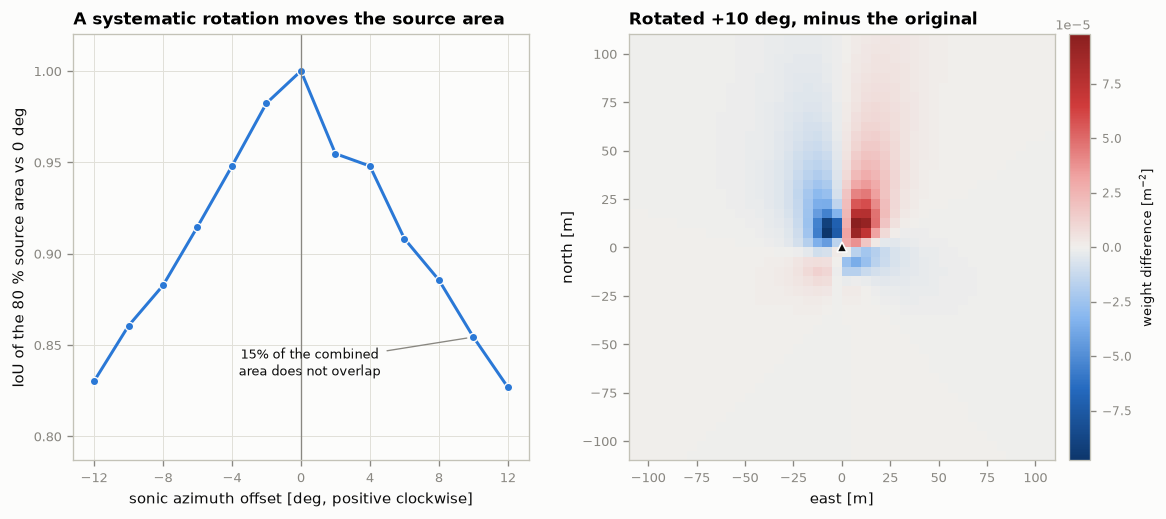

In [23]:
rot10 = rotate_climatology(result.w_mean, 10.0)
diff = rot10 - result.w_mean
lim = float(np.abs(diff).max())

fig, (ax_i, ax_d) = plt.subplots(1, 2, figsize=(9.8, 4.4),
                                 gridspec_kw={"width_ratios": [1, 1.05]})

ax_i.plot(offsets, iou_curve, color=C_BLUE, marker="o", markersize=5,
          markeredgecolor=SURFACE, markeredgewidth=0.8)
ax_i.axvline(0, color=MUTED, linewidth=0.8)
ax_i.annotate(f"{1 - iou[10]:.0%} of the combined\narea does not overlap",
              xy=(10, iou[10]), xytext=(0.5, iou_curve.min() + 0.004),
              fontsize=8, color=INK, ha="center", va="bottom",
              arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 0.8,
                          "shrinkA": 2, "shrinkB": 4})
ax_i.set_xlabel("sonic azimuth offset [deg, positive clockwise]")
ax_i.set_ylabel("IoU of the 80 % source area vs 0 deg")
ax_i.set_xticks(offsets[::2])
ax_i.set_ylim(iou_curve.min() - 0.04, 1.02)
ax_i.set_title("A systematic rotation moves the source area")

im = ax_d.imshow(diff, origin="upper", extent=EXTENT, cmap=CM_DIFF,
                 vmin=-lim, vmax=lim, interpolation="nearest")
ax_d.plot(0, 0, marker="^", markersize=6, color=INK,
          markeredgecolor=SURFACE, markeredgewidth=1.0, zorder=5)
ax_d.set_xlabel("east [m]")
ax_d.set_ylabel("north [m]")
ax_d.set_xlim(-110, 110)
ax_d.set_ylim(-110, 110)
ax_d.set_aspect("equal")
ax_d.set_title("Rotated +10 deg, minus the original")
ax_d.grid(False)
cb = fig.colorbar(im, ax=ax_d, fraction=0.046, pad=0.03)
cb.set_label("weight difference [m$^{-2}$]", fontsize=8)
cb.ax.tick_params(labelsize=7)
cb.formatter.set_powerlimits((0, 0))
fig.tight_layout()
plt.show()

A ±10° azimuth offset — not an unusual magnitude for a compass-set sonic —
leaves about 15 % of the combined 80 % source area non-overlapping. Set that
against the bootstrap margin from §8, which was 15–20 % of the core. **The two
error sources are comparable in size at this site**, and only one of them
appears in `p_include_80`. A footprint uncertainty statement that reports the
bootstrap alone is reporting about half the story.

The right way to use this is as a scenario, not a correction: rotate by the
instrument's stated azimuth tolerance, recompute whatever downstream quantity
the footprint feeds, and report the range. The module docstring's caveat applies
here too — a coherent rotation error in the model itself would be invisible to
the bootstrap for exactly the same reason.

## 11. Phase 3 — write the GeoTIFF

`write_geotiff` projects the tower's latitude and longitude into the grid's CRS,
builds the affine transform from the grid geometry, and writes every band into
one tiled, deflate-compressed float32 GeoTIFF with the band names set as
descriptions and the run metadata as tags.

Band descriptions and tags are what make the file self-documenting six months
later, so the read-back below checks them rather than assuming.

In [24]:
tif_path = WORK / f"{SITE}_footprint_uncertainty.tif"
write_geotiff(result, str(tif_path), compress="deflate")

with rasterio.open(tif_path) as src:
    print(f"{tif_path.name}  ({tif_path.stat().st_size / 1024:.0f} KB)")
    print(f"  crs        {src.crs}")
    print(f"  size       {src.width} x {src.height} at {src.res[0]:g} m")
    print(f"  bounds     {src.bounds.left:.1f}, {src.bounds.bottom:.1f} to "
          f"{src.bounds.right:.1f}, {src.bounds.top:.1f}")
    print(f"  dtype      {src.dtypes[0]}, nodata {src.nodatavals[0]}")
    print("  bands")
    for i, name in enumerate(src.descriptions, start=1):
        band = src.read(i, masked=True)
        print(f"    {i}. {name:<14} {band.min():.3g} .. {band.max():.3g}")
    print("  tags")
    for key in ("n_blocks", "n_periods", "n_members", "n_dropped",
                "levels", "mean_capture", "min_capture", "seed", "note"):
        print(f"    {key:<14} {src.tags().get(key)}")

US-UTE_footprint_uncertainty.tif  (232 KB)
  crs        EPSG:32612
  size       120 x 120 at 5 m
  bounds     449405.5, 4176300.0 to 450005.5, 4176900.0
  dtype      float32, nodata nan
  bands
    1. p_include_50   0 .. 1
    2. p_include_80   0 .. 1
    3. p_include_90   0 .. 1
    4. w_mean         1.88e-09 .. 0.000871
    5. w_p05          1.12e-09 .. 0.000825
    6. w_p50          1.85e-09 .. 0.000872
    7. w_p95          2.7e-09 .. 0.000917
    8. w_cv           0.0226 .. 0.142
  tags
    n_blocks       75
    n_periods      3271
    n_members      500
    n_dropped      0
    levels         0.5,0.8,0.9
    mean_capture   0.9553053634692791
    min_capture    0.9500000000000001
    seed           0
    note           weights are m^-2 densities; p_include is a probability in [0,1]


In [25]:
# Confirm the georeferencing puts the tower where it belongs: the centre of the
# raster should land on the tower's projected coordinates.
from pyproj import Transformer

with rasterio.open(tif_path) as src:
    cx, cy = src.xy(src.height // 2, src.width // 2)

east, north = Transformer.from_crs("EPSG:4326", CRS, always_xy=True).transform(
    TOWER_LON, TOWER_LAT
)
print(f"tower projected to  {east:.1f}, {north:.1f}")
print(f"raster centre at    {cx:.1f}, {cy:.1f}")
print(f"offset              {abs(cx - east):.1f}, {abs(cy - north):.1f} m "
      f"(expected <= half a cell, {grid.dx / 2:g} m)")

tower projected to  449705.5, 4176600.0
raster centre at    449708.0, 4176597.5
offset              2.5, 2.5 m (expected <= half a cell, 2.5 m)


## 12. What to carry away

**The workflow, in four lines.**

```python
grid   = GridSpec.square(half_width=300.0, dx=5.0, tower_lat=..., tower_lon=...)
blocks = accumulate_blocks(season, grid, ffp_adapter(grid, z_m, z_0), block_days=1)
result = block_bootstrap(blocks, n_members=500, levels=(0.5, 0.8, 0.9), seed=0)
write_geotiff(result, "site_footprint_uncertainty.tif")
```

**The checks that decide whether the output means anything.**

| check | where | what it should say |
|---|---|---|
| captured fraction | `blocks.mean_capture` | near 1; and `max(levels)` well below it |
| block count | `blocks.n_blocks` | ≥ 20–30, else the module warns |
| block length | your choice | ≥ one diurnal cycle; justify it from the autocorrelation |
| members dropped | `result.n_dropped` | 0, or a stated small fraction |
| seed | `result.meta["seed"]` | set, and recorded |

**The three claims this notebook supports.**

1. `p_include_{R}` replaces the hard contour with a core and a margin. At
   US-UTE the 80 % source area is 0.65 ha of core with 0.10 ha of genuinely
   ambiguous edge — and any statistic that turns on that edge needs the
   uncertainty attached.
2. **Block length is a modelling decision with a defensible range, not a
   default.** One day is the floor set by the diurnal cycle; three days is the
   ceiling set by keeping enough blocks. Report the range, not one setting.
3. **The bootstrap is half the error budget.** A ±10° sonic azimuth offset
   displaces as much of the source area as the entire sampling interval, and no
   amount of resampling will reveal it. Probe it separately with
   `rotate_climatology`.

**Where to go next.** `p_include_80` multiplies naturally against a land-cover
raster to give a *probability-weighted* composition rather than a hard-masked
one — see [`openet_masking`](../fluxfootprints.rst) for the masking utilities and
the [representativeness worked example](representativeness_example.ipynb) for the
Chu et al. (2021) target-area comparison this feeds into.